# Week 04 (Data Preprocessing and Preparation)

---

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

ImportError: DLL load failed while importing cython_blas: An Application Control policy has blocked this file.

In [ ]:
import numpy as np
from sklearn import datasets
import pandas as pd

# Load the iris dataset
bunga = datasets.load_iris()

# Create a DataFrame from the iris dataset
df_iris = pd.DataFrame(data=bunga.data, columns=bunga.feature_names)

# Add the target variable (species) to the DataFrame
df_iris['target'] = bunga.target

# Convert the integer target to the actual species name for better readability
#df_iris['species'] = pd.Categorical.from_codes(bunga.target, bunga.target_names)

# Introduce NaN values randomly in the dataset
# Set a random seed for reproducibility
np.random.seed(0)

# Introduce NaN values in 5% of the data
nan_indices = np.random.choice(df_iris.index, size=int(0.05 * df_iris.size), replace=True)
nan_columns = np.random.choice(df_iris.columns, size=int(0.05 * df_iris.size), replace=True)

# Assign NaN values
for idx, col in zip(nan_indices, nan_columns):
    df_iris.at[idx, col] = np.nan

# Display the first few rows of the DataFrame to show NaN values
print(df_iris.head())


ImportError: DLL load failed while importing _ufuncs_cxx: An Application Control policy has blocked this file.

In [ ]:
df_iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  144 non-null    float64
 1   sepal width (cm)   144 non-null    float64
 2   petal length (cm)  145 non-null    float64
 3   petal width (cm)   143 non-null    float64
 4   target             140 non-null    float64
dtypes: float64(5)
memory usage: 6.0 KB


In [ ]:
#Summary Statistics
df_iris.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,144.000000,144.000000,145.000000,143.000000,140.000000
mean,5.839583,3.060417,3.754483,1.219580,0.985714
std,0.815687,0.434237,1.780410,0.755101,0.813428
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.400000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [ ]:
#Finding the percentage of missing data
nulls = df_iris.isnull().sum()
nulls_percentage = nulls[nulls!=0]/df_iris.shape[0]*100
print(round(nulls_percentage,2))

sepal length (cm)    4.00
sepal width (cm)     4.00
petal length (cm)    3.33
petal width (cm)     4.67
target               6.67
dtype: float64


In [ ]:
df_iris[df_iris.isna().any(axis=1)]

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
9,NaN,3.1,1.5,0.1,NaN
21,5.1,NaN,1.5,0.4,0.0
25,5.0,3.0,1.6,NaN,0.0
28,5.2,3.4,1.4,NaN,0.0
29,4.7,3.2,1.6,NaN,0.0
31,NaN,3.4,1.5,0.4,0.0
32,5.2,4.1,1.5,NaN,NaN
34,4.9,3.1,NaN,0.2,0.0
36,5.5,3.5,1.3,0.2,NaN
39,5.1,NaN,1.5,0.2,0.0


In [ ]:
df_iris

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2.0
146,6.3,2.5,5.0,1.9,2.0
147,6.5,3.0,5.2,2.0,NaN
148,6.2,3.4,5.4,NaN,2.0


In [ ]:
df_drop=df_iris.dropna()
df_drop.shape

(119, 5)

In [ ]:
df_drop

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0
...,...,...,...,...,...
143,6.8,3.2,5.9,2.3,2.0
144,6.7,3.3,5.7,2.5,2.0
145,6.7,3.0,5.2,2.3,2.0
146,6.3,2.5,5.0,1.9,2.0


In [ ]:
df_konstan=df_iris.fillna(0) # fill NaN with zero
df_konstan.shape

(150, 5)

In [ ]:
df_konstan

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2.0
146,6.3,2.5,5.0,1.9,2.0
147,6.5,3.0,5.2,2.0,0.0
148,6.2,3.4,5.4,0.0,2.0


In [ ]:
# Fill NaN values with mean for only numeric columns
df_mean = df_iris.fillna(df_iris.select_dtypes(include='number').mean())

# Display the shape of the resulting DataFrame
df_mean.shape

(150, 5)

In [ ]:
df_mean=df_iris.fillna(df_iris.mean()) # fill NaN with mean
df_mean.shape

(150, 5)

In [ ]:
df_mean

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.20000,0.000000
1,4.9,3.0,1.4,0.20000,0.000000
2,4.7,3.2,1.3,0.20000,0.000000
3,4.6,3.1,1.5,0.20000,0.000000
4,5.0,3.6,1.4,0.20000,0.000000
...,...,...,...,...,...
145,6.7,3.0,5.2,2.30000,2.000000
146,6.3,2.5,5.0,1.90000,2.000000
147,6.5,3.0,5.2,2.00000,0.985714
148,6.2,3.4,5.4,1.21958,2.000000


<Axes: >

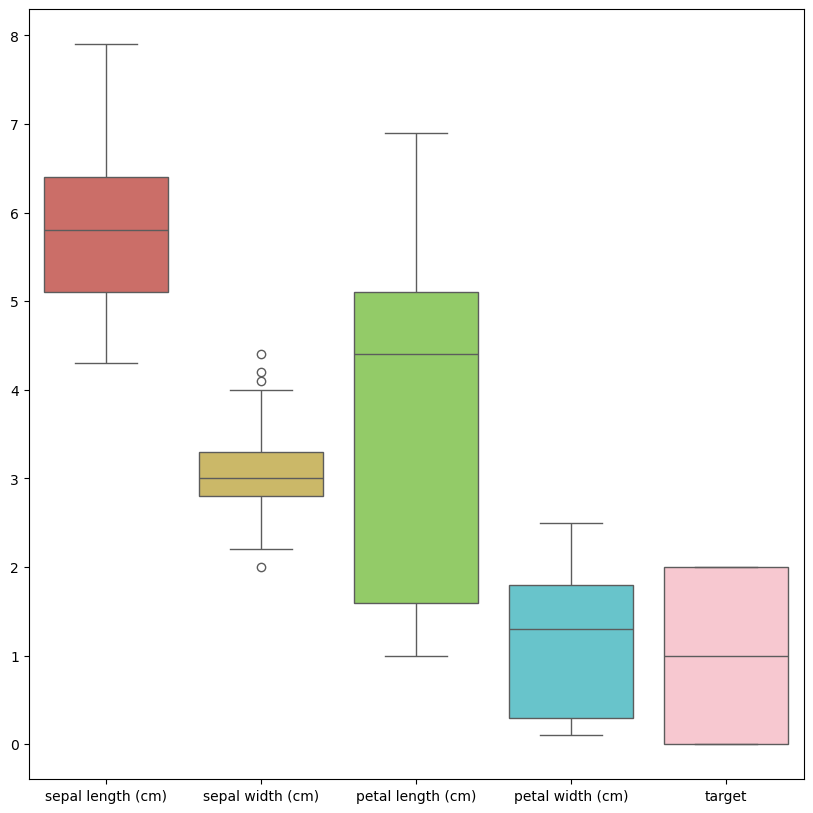

In [ ]:
fig, ax = plt.subplots(figsize=(10,10))
sns.boxplot(data=df_iris, palette=('#db5f57','#dbc257','#91db57','#57d3db','pink'))

In [ ]:
# Select data with outlier, will be resolved using Zscore
data_sepal = df_drop[['sepal width (cm)']]
data_sepal

,sepal width (cm)
0,3.5
1,3.0
2,3.2
3,3.1
4,3.6
...,...
143,3.2
144,3.3
145,3.0
146,2.5


In [ ]:
stats.zscore(data_sepal, nan_policy='omit')

,sepal width (cm)
0,1.004480
1,-0.123191
2,0.327877
3,0.102343
4,1.230014
...,...
143,0.327877
144,0.553412
145,-0.123191
146,-1.250862


In [ ]:
# Get data inside 3 sigma

data_zscore=data_sepal[(np.abs(stats.zscore(data_sepal, nan_policy='omit')) < 3).all(axis=1)]
data_zscore.shape

(118, 1)

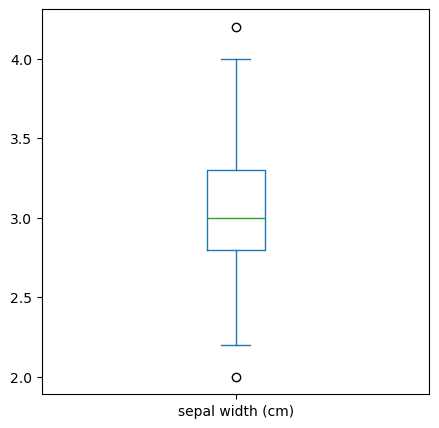

In [ ]:
data_zscore.plot(kind='box', figsize=(5,5))
plt.show()

In [ ]:
# Handling Outlier with IQR

# Q1, Q3, dan interquartile range
Q1 = data_sepal.quantile(q=.25)
Q3 = data_sepal.quantile(q=.75)
IQR = Q3 - Q1 #IQR=Q3-Q1 or use stats.iqr from scipy

# Take value 1.5*IQR from Qi and Q3
data_iqr = data_sepal[-((data_sepal < (Q1-1.5*IQR)) | (data_sepal > (Q3+1.5*IQR))).any(axis=1)]
data_iqr.shape

(116, 1)

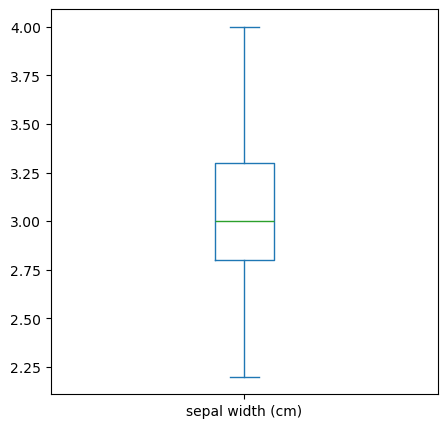

In [ ]:
data_iqr.plot(kind='box', figsize=(5,5))
plt.show()

In [ ]:
data_zscore.columns = ['Z-Score']
data_iqr.columns = ['IQR']

In [ ]:
result = pd.concat([data_sepal, data_zscore, data_iqr], axis=1)

<Axes: >

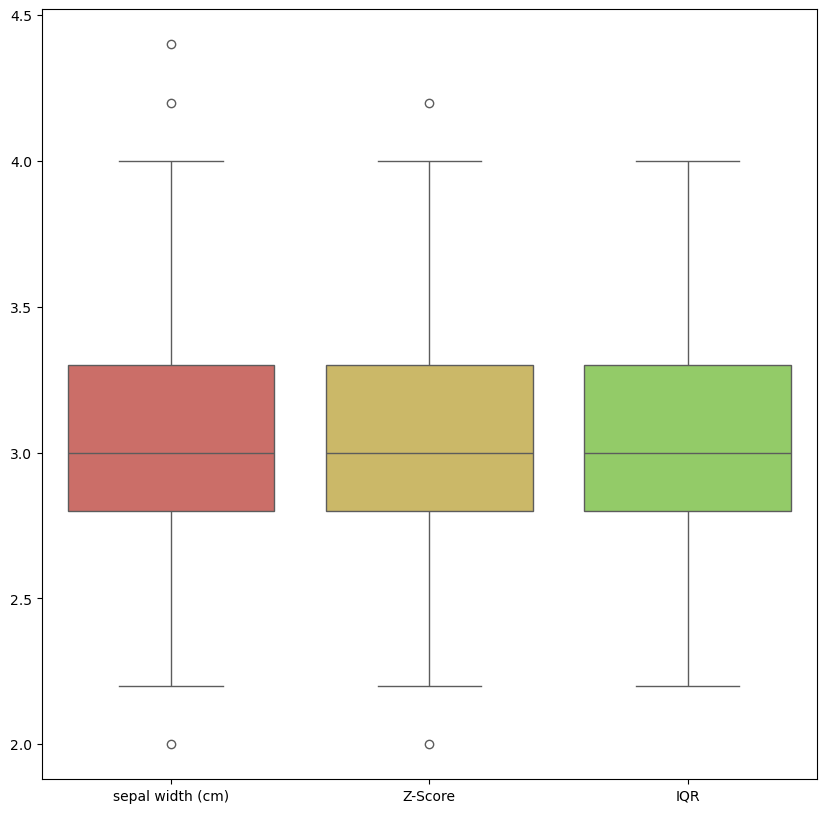

In [ ]:
fig, ax = plt.subplots(figsize=(10,10))
sns.boxplot(data=result, palette=('#db5f57','#dbc257','#91db57'))

In [ ]:
# Train Test Split, basic for Next Week about machine learning, especially classification
import numpy as np
from sklearn.model_selection import train_test_split

In [ ]:
df_mean

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.20000,0.000000
1,4.9,3.0,1.4,0.20000,0.000000
2,4.7,3.2,1.3,0.20000,0.000000
3,4.6,3.1,1.5,0.20000,0.000000
4,5.0,3.6,1.4,0.20000,0.000000
...,...,...,...,...,...
145,6.7,3.0,5.2,2.30000,2.000000
146,6.3,2.5,5.0,1.90000,2.000000
147,6.5,3.0,5.2,2.00000,0.985714
148,6.2,3.4,5.4,1.21958,2.000000


In [ ]:
x = df_drop[['sepal width (cm)','petal length (cm)','petal width (cm)','target']]
y = df_drop[['sepal length (cm)']]

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=5)

In [ ]:
print(x_train.shape, x_test.shape)
print(y_train.shape, y_test.shape)

(83, 4) (36, 4)
(83, 1) (36, 1)


In [ ]:
pip install pandas xlrd

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Encoding, we need to get the superstore data first
store = pd.read_excel("samplestore.xls")
store.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2021-103800,2021-01-03,2021-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2021-112326,2021-01-04,2021-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2021-112326,2021-01-04,2021-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2021-112326,2021-01-04,2021-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2021-141817,2021-01-05,2021-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [ ]:
store.groupby('City')['Row ID'].nunique()

City
Aberdeen        1
Abilene         1
Akron          21
Albuquerque    14
Alexandria     16
               ..
Woonsocket      4
Yonkers        15
York            5
Yucaipa         1
Yuma            4
Name: Row ID, Length: 542, dtype: int64

In [ ]:
# Choosing column
store_cut = store[['Order ID','Order Date','Ship Date','Ship Mode','City']]
store_cut.head()

,Order ID,Order Date,Ship Date,Ship Mode,City
0,US-2021-103800,2021-01-03,2021-01-07,Standard Class,Houston
1,US-2021-112326,2021-01-04,2021-01-08,Standard Class,Naperville
2,US-2021-112326,2021-01-04,2021-01-08,Standard Class,Naperville
3,US-2021-112326,2021-01-04,2021-01-08,Standard Class,Naperville
4,US-2021-141817,2021-01-05,2021-01-12,Standard Class,Philadelphia


In [ ]:
# Encoding State Data
store_cut['City'] = store_cut['City'].astype('category')
store_cut['Postal Code'] = store_cut['City'].cat.codes
store_cut.head()

C:\Users\user\AppData\Local\Temp\ipykernel_22596\1621709042.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  store_cut['City'] = store_cut['City'].astype('category')
C:\Users\user\AppData\Local\Temp\ipykernel_22596\1621709042.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  store_cut['Postal Code'] = store_cut['City'].cat.codes


,Order ID,Order Date,Ship Date,Ship Mode,City,Postal Code
0,US-2021-103800,2021-01-03,2021-01-07,Standard Class,Houston,211
1,US-2021-112326,2021-01-04,2021-01-08,Standard Class,Naperville,327
2,US-2021-112326,2021-01-04,2021-01-08,Standard Class,Naperville,327
3,US-2021-112326,2021-01-04,2021-01-08,Standard Class,Naperville,327
4,US-2021-141817,2021-01-05,2021-01-12,Standard Class,Philadelphia,380


In [ ]:
# Ensure to use .loc[] to avoid SettingWithCopyWarning
store_cut.loc[:, 'City'] = store_cut['City'].astype('category')
store_cut.loc[:, 'Postal Code'] = store_cut['City'].cat.codes
store_cut.head()

,Order ID,Order Date,Ship Date,Ship Mode,City,Postal Code
0,US-2021-103800,2021-01-03,2021-01-07,Standard Class,Houston,211
1,US-2021-112326,2021-01-04,2021-01-08,Standard Class,Naperville,327
2,US-2021-112326,2021-01-04,2021-01-08,Standard Class,Naperville,327
3,US-2021-112326,2021-01-04,2021-01-08,Standard Class,Naperville,327
4,US-2021-141817,2021-01-05,2021-01-12,Standard Class,Philadelphia,380


In [ ]:
# One-hot encoding Ship Mode

one_hot = pd.get_dummies(store_cut['Ship Mode'])
# Drop column B as it is now encoded
#df = df.drop('B', axis = 1)
# Join the encoded df
store_cut = store_cut.join(one_hot)
store_cut.head()

,Order ID,Order Date,Ship Date,Ship Mode,City,Postal Code,First Class,Same Day,Second Class,Standard Class
0,US-2021-103800,2021-01-03,2021-01-07,Standard Class,Houston,211,False,False,False,True
1,US-2021-112326,2021-01-04,2021-01-08,Standard Class,Naperville,327,False,False,False,True
2,US-2021-112326,2021-01-04,2021-01-08,Standard Class,Naperville,327,False,False,False,True
3,US-2021-112326,2021-01-04,2021-01-08,Standard Class,Naperville,327,False,False,False,True
4,US-2021-141817,2021-01-05,2021-01-12,Standard Class,Philadelphia,380,False,False,False,True


In [ ]:
import pandas as pd

# Assuming store_cut is already defined and loaded with your data

# One-hot encoding 'Ship Mode'
one_hot = pd.get_dummies(store_cut['Ship Mode'])

# Convert boolean True/False to 1/0
one_hot = one_hot.astype(int)

# Drop the original 'Ship Mode' column if no longer needed
store_cut = store_cut.drop('Ship Mode', axis=1)

# Join the one-hot encoded columns back to the original DataFrame
store_cut = store_cut.join(one_hot)

# Display the first few rows of the updated DataFrame
print(store_cut.head())


         Order ID Order Date  Ship Date          City  Postal Code  \
0  US-2021-103800 2021-01-03 2021-01-07       Houston          211   
1  US-2021-112326 2021-01-04 2021-01-08    Naperville          327   
2  US-2021-112326 2021-01-04 2021-01-08    Naperville          327   
3  US-2021-112326 2021-01-04 2021-01-08    Naperville          327   
4  US-2021-141817 2021-01-05 2021-01-12  Philadelphia          380   

   First Class  Same Day  Second Class  Standard Class  
0            0         0             0               1  
1            0         0             0               1  
2            0         0             0               1  
3            0         0             0               1  
4            0         0             0               1  


In [ ]:
store_cut.head()

,Order ID,Order Date,Ship Date,City,Postal Code,First Class,Same Day,Second Class,Standard Class
0,US-2021-103800,2021-01-03,2021-01-07,Houston,211,0,0,0,1
1,US-2021-112326,2021-01-04,2021-01-08,Naperville,327,0,0,0,1
2,US-2021-112326,2021-01-04,2021-01-08,Naperville,327,0,0,0,1
3,US-2021-112326,2021-01-04,2021-01-08,Naperville,327,0,0,0,1
4,US-2021-141817,2021-01-05,2021-01-12,Philadelphia,380,0,0,0,1


----